# Sequence alignment from scratch

Lecture 3, Sequence Analysis. We turn the Needleman-Wunsch recurrence from the blackboard into code, test it on our blackboard examples, and align two full proteins.

**Finished version** with all outputs.

In [1]:
# In Colab, Biopython is not installed by default
try:
    import Bio
except ImportError:
    %pip install biopython

import random
import time

import matplotlib.pyplot as plt
from Bio.Align import substitution_matrices

## 1. Score two letters

Our simple scoring from the blackboard: match +1, mismatch −1, gap −1.

In [2]:
def simple_score(x, y):
    """+1 if the letters are the same, -1 if not."""
    return 1 if x == y else -1

GAP = -1

## 2. Fill the matrix

$F(i, j)$ is the best score for the first $i$ letters of $a$ and the first $j$ letters of $b$:

$$F(i,j) = \max \begin{cases} F(i-1, j-1) + s(a_i, b_j) \\ F(i-1, j) + g \\ F(i, j-1) + g \end{cases}$$

Python counts from 0, so letter $a_i$ is `a[i - 1]`.

In [3]:
def needleman_wunsch(a, b, score, gap):
    """Fill the alignment matrix F for sequences a and b."""
    F = [[0] * (len(b) + 1) for _ in range(len(a) + 1)]
    for i in range(1, len(a) + 1):          # letters of a against nothing
        F[i][0] = i * gap
    for j in range(1, len(b) + 1):          # letters of b against nothing
        F[0][j] = j * gap
    for i in range(1, len(a) + 1):
        for j in range(1, len(b) + 1):
            pair = F[i - 1][j - 1] + score(a[i - 1], b[j - 1])   # pair a_i with b_j
            gap_in_b = F[i - 1][j] + gap                         # a_i against a gap
            gap_in_a = F[i][j - 1] + gap                         # b_j against a gap
            F[i][j] = max(pair, gap_in_b, gap_in_a)
    return F

## 3. Trace back

Start at the bottom-right corner and ask which of the three options produced the value.

In [4]:
def traceback(F, a, b, score, gap):
    """Rebuild one optimal alignment from the filled matrix."""
    top, bottom = [], []
    i, j = len(a), len(b)
    while i > 0 or j > 0:
        if i > 0 and j > 0 and F[i][j] == F[i - 1][j - 1] + score(a[i - 1], b[j - 1]):
            top.append(a[i - 1]); bottom.append(b[j - 1]); i -= 1; j -= 1   # pair
        elif i > 0 and F[i][j] == F[i - 1][j] + gap:
            top.append(a[i - 1]); bottom.append("-"); i -= 1              # gap in b
        else:
            top.append("-"); bottom.append(b[j - 1]); j -= 1              # gap in a
    return "".join(reversed(top)), "".join(reversed(bottom))


def show(top, bottom, width=60):
    """Print an alignment in blocks, with | for identical letters."""
    bars = "".join("|" if x == y else " " for x, y in zip(top, bottom))
    for k in range(0, len(top), width):
        print(top[k:k + width]); print(bars[k:k + width]); print(bottom[k:k + width]); print()


def identity(top, bottom):
    """Identical positions divided by alignment length (as BLAST counts it)."""
    return sum(x == y for x, y in zip(top, bottom)) / len(top)

## 4. Test on the blackboard examples

Expected: `DART / CA-T` with score 0, `K-LHL / KVL-L` with score 1.

In [5]:
for a, b in [("DART", "CAT"), ("KLHL", "KVLL")]:
    F = needleman_wunsch(a, b, simple_score, GAP)
    top, bottom = traceback(F, a, b, simple_score, GAP)
    print("score", F[-1][-1])
    show(top, bottom)

score 0
DART
 | |
CA-T

score 1
K-LHL
| | |
KVL-L



## 5. Two full proteins

Our protein against TEM-1 (UniProt P62593), scored with BLOSUM62 and a gap penalty of −8.

In [6]:
our_protein = (
    "MNVIIKAVVTASTLLMVSFSSFETSAQSPLLKEQIESIVIGKKATVGVAVWGPDDLEPLL"
    "INPFEKFPMQSVFKLHLAMLVLHQVDQGKLDLNQTVIVNRAKVLQNTWAPIMKAYQGDEF"
    "SVPVQQLLQYSVSHSDNVACDLLFELVGGPAALHDYIQSMGIKETAVVANEAQMHADDQV"
    "QYQNWTSMKGAAEILKKFEQKTQLSETSQALLWKWMVETTTGPERLKGLLPAGTVVAHKT"
    "GTSGIKAGKTAATNDLGIILLPDGRPLLVAVFVKDSAESSRTNEAIIAQVAQTAYQFELK"
    "KLSALSPN"
)

tem1 = (
    "MSIQHFRVALIPFFAAFCLPVFAHPETLVKVKDAEDQLGARVGYIELDLNSGKILESFRP"
    "EERFPMMSTFKVLLCGAVLSRVDAGQEQLGRRIHYSQNDLVEYSPVTEKHLTDGMTVREL"
    "CSAAITMSDNTAANLLLTTIGGPKELTAFLHNMGDHVTRLDRWEPELNEAIPNDERDTTM"
    "PAAMATTLRKLLTGELLTLASRQQLIDWMEADKVAGPLLRSALPAGWFIADKSGAGERGS"
    "RGIIAALGPDGKPSRIVVIYTTGSQATMDERNRQIAEIGASLIKHW"
)

blosum62 = substitution_matrices.load("BLOSUM62")


def blosum_score(x, y):
    return blosum62[x][y]


start = time.time()
F = needleman_wunsch(our_protein, tem1, blosum_score, -8)
seconds = time.time() - start
top, bottom = traceback(F, our_protein, tem1, blosum_score, -8)
print(f"score {F[-1][-1]:.0f}, identity {identity(top, bottom):.1%}, "
      f"{len(our_protein)} x {len(tem1)} cells in {seconds:.2f} s\n")
show(top, bottom)

score 87, identity 24.8%, 308 x 286 cells in 0.13 s

MNVIIKAVVTASTLLMVSFSSFETSAQSPLLKEQIESIVIGKKATVGVAVWGPDDLEPL-
|      |             |       | |        |  | ||           | 
MSIQHFRVALIPFFAAFCLPVF-AHPET-LVKVKDAEDQLG--ARVGYIELDLNSGKILE

LINPFEKFPMQSVFKLHLAMLVLHQVDQGKLDLNQTVIVNRAKVLQNTWAPIMKAYQGDE
   | | ||| | ||  |   ||  || |   |                 |       | 
SFRPEERFPMMSTFKVLLCGAVLSRVDAGQEQLGRRIHYSQNDLVE--YSPVTEKHLTD-

FSVPVQQLLQYSVSHSDNVACDLLFELVGGPAALHDYIQSMGIKETAVVANEAQMHADDQ
    |  |       ||| |  ||    |||  |      ||   |     |        
-GMTVRELCSAAITMSDNTAANLLLTTIGGPKELTAFLHNMGDHVTRLDRWEPELNEAIP

VQYQNWTSMKGAAEILKKFEQKTQLSETSQALLWKWM-VETTTGPERLKGLLPAGTVVAH
      |     |  | |      |   |   |  ||      ||  |   ||||   | 
NDERDTTMPAAMATTLRKLLTGELLTLASRQQLIDWMEADKVAGP-LLRSALPAGWFIAD

KTGTSGIKAGKTAATNDLGIILLPDGRPLLVAVFVKDSAESSRTNEAIIAQVAQTAYQFE
| |  |   |       ||    ||| |    |       |  |         | |   |
KSG-AG-ERGSRGIIAALG----PDGKPSRIVV-IYTTG-SQATMDE--RN-RQIA---E

LKKLSALSPN
    |     
I-GAS

## 6. Is that significant?

Shuffle TEM-1: same amino acids, no evolutionary relationship. What scores and identities do unrelated proteins reach?

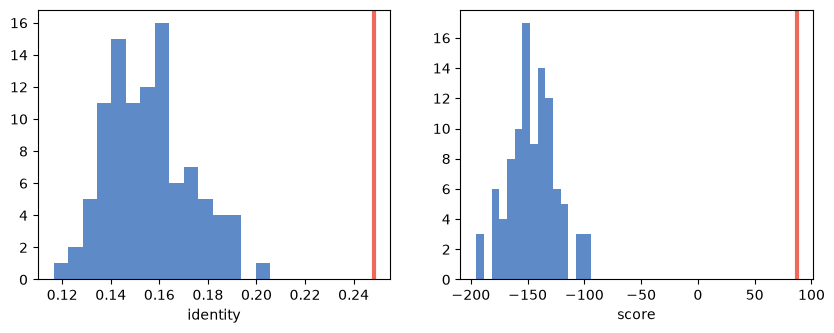

shuffled: identity up to 20.6%, score up to -94


In [7]:
random.seed(1)
shuffled_scores, shuffled_identities = [], []
for _ in range(100):
    shuffled = "".join(random.sample(tem1, len(tem1)))
    Fs = needleman_wunsch(our_protein, shuffled, blosum_score, -8)
    shuffled_scores.append(Fs[-1][-1])
    shuffled_identities.append(identity(*traceback(Fs, our_protein, shuffled, blosum_score, -8)))

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.5))
left.hist(shuffled_identities, bins=15, color="#5E8AC7")
left.axvline(identity(top, bottom), color="#ED6A5B", lw=3)
left.set_xlabel("identity")
right.hist(shuffled_scores, bins=15, color="#5E8AC7")
right.axvline(F[-1][-1], color="#ED6A5B", lw=3)
right.set_xlabel("score")
plt.show()
print(f"shuffled: identity up to {max(shuffled_identities):.1%}, score up to {max(shuffled_scores):.0f}")

## 7. How long would a database search take?

The matrix has len(a) × len(b) cells. Swiss-Prot holds about 209 million amino acids.

In [8]:
cells_per_second = len(our_protein) * len(tem1) / seconds
swissprot_letters = 209_017_843   # Swiss-Prot release 2026_03
hours = len(our_protein) * swissprot_letters / cells_per_second / 3600
print(f"{cells_per_second:,.0f} cells per second -> about {hours:.0f} hours for Swiss-Prot")

674,055 cells per second -> about 27 hours for Swiss-Prot


## 8. Extra: local alignment (Smith-Waterman)

Two changes: no cell drops below 0 (a new alignment can start anywhere), and the traceback starts at the best cell anywhere and stops at 0. Cft2 (UniProt D6MLX4) carries two sigma factor domains and then a beta-lactamase domain.

In [9]:
cft2 = (
    "MHQWPAKSVNMRIENTSASALPTLREELVQLADDDYQAHNDEDLFYDAAKGDTDAFGELV"
    "RRNYGIVYAVGLARLGQRDEAEDLAQEVFLRAFLLLDRLDDPAKFPHWLTRIARNLSVDW"
    "QRRGTRAKRLVSMVPMTGLELPASTTDARDAASLSEQNAALQTALDGLAPPQREIILLHY"
    "MEGLSHGEIALRLAVARSTVSRQIARAVDAMRGFVDANLKESTAQLRPRKGAAGRTLSIL"
    "VAVTTLSAKSRNSLAAQANFPIPGNAVPSQEAVQLWNEIKSLFWSGARRLLFKTAMAVGA"
    "VGVIVPLGYWYCESPAQAVQNATPQASPGAAPSPGGPKTADLSQRLAEIARRAGGQVGVS"
    "VMNIENGDSADFNGDEPRSLYSVFKFPVAVAVLKDVETGKLKLDQKVAVKKSDLSGTAPS"
    "SSNRWQNMPVTYTVQQLLEFAMIESDNTAVDKLLTLVGGPSTVTKQIQSLGISGIEMAAD"
    "SREAAKLADHPNTGSANAIVRLLAGLQKGEVLKPAERTVLWDMMQRATTGVKRLRAGLPA"
    "RTVLMHKTGTGPNDSGTNDVGIINLPDGKGHLAIAVLINKSTLSSASQEQVIAAIAAAAW"
    "DAMTQQ"
)


def smith_waterman(a, b, score, gap):
    """Fill the local alignment matrix; return it and the best cell."""
    F = [[0] * (len(b) + 1) for _ in range(len(a) + 1)]
    best = (0, 0, 0)   # score, i, j
    for i in range(1, len(a) + 1):
        for j in range(1, len(b) + 1):
            F[i][j] = max(0,                                            # start anew
                          F[i - 1][j - 1] + score(a[i - 1], b[j - 1]),
                          F[i - 1][j] + gap,
                          F[i][j - 1] + gap)
            best = max(best, (F[i][j], i, j))
    return F, best


def local_traceback(F, a, b, score, gap, i, j):
    """Walk back from cell (i, j) until the score drops to 0."""
    top, bottom = [], []
    while F[i][j] > 0:
        if F[i][j] == F[i - 1][j - 1] + score(a[i - 1], b[j - 1]):
            top.append(a[i - 1]); bottom.append(b[j - 1]); i -= 1; j -= 1
        elif F[i][j] == F[i - 1][j] + gap:
            top.append(a[i - 1]); bottom.append("-"); i -= 1
        else:
            top.append("-"); bottom.append(b[j - 1]); j -= 1
    return "".join(reversed(top)), "".join(reversed(bottom)), j   # j: start in b


G = needleman_wunsch(our_protein, cft2, blosum_score, -8)
print(f"global: score {G[-1][-1]:.0f}")
L, (best, i, j) = smith_waterman(our_protein, cft2, blosum_score, -8)
top, bottom, start = local_traceback(L, our_protein, cft2, blosum_score, -8, i, j)
print(f"local: score {best:.0f}, Cft2 residues {start + 1}-{j}, identity {identity(top, bottom):.1%}\n")
show(top, bottom)

global: score -1740


local: score 333, Cft2 residues 342-601, identity 34.8%

LKEQIESIVIGKKATVGVAVWGPDDLEPLLINPFEKFPMQSVFKLHLAMLVLHQVDQGKL
|      |       ||| |           |  |     ||||   |  ||  |  |||
LSQRLAEIARRAGGQVGVSVMNIENGDSADFNGDEPRSLYSVFKFPVAVAVLKDVETGKL

DLNQTVIVNRAKVLQNTWAPIMKAYQGDEFSVPVQQLLQYSVSHSDNVACDLLFELVGGP
 | | | |     |  |        |       |||||      ||| | | |  |||||
KLDQKVAVKKSD-LSGTAPSSSNRWQNMPVTYTVQQLLEFAMIESDNTAVDKLLTLVGGP

AALHDYIQSMGIKETAVVANEAQMHADDQVQYQNWTSMKGAAEILKKFEQKTQLSETSQA
      ||| ||      |      |       |  |       |        |      
STVTKQIQSLGISGIEMAA-DSR-EAAKLADHPNTGSANAIVRLLAGLQKGEVLKPAERT

LLWKWMVETTTGPERLKGLLPAGTVVAHKTGTSGIKAGKTAATNDLGIILLPDGR-PLLV
 ||  |   |||  ||   ||| ||  ||||| |        ||| ||| ||||   |  
VLWDMMQRATTGVKRLRAGLPARTVLMHKTGT-G--P-NDSGTNDVGIINLPDGKGHLAI

AVFVKDSAESSRTNEAIIAQVAQTAYQ
||    |  ||   |  ||  |  |  
AVLINKSTLSSASQEQVIAAIAAAAWD

